In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))

import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt

from config import (
    OHLCV_DIR, ASSET_DAILY_PATH, ASSETS_PATH,
    DATE_COL, TIMESTAMP_COL, CLOSE_COL, ASSET_ID_COL, MARKET_SYMBOL_COL,
)
from helperfunctions import HelperFunctions
helper = HelperFunctions()

print("Imports OK")

Imports OK


In [2]:
# --- Daten laden & vorverarbeiten ---
from helperfunctions import STABLECOIN_SYMBOLS

# Assets-Tabelle: asset_id <-> symbol
assets_df  = pd.read_parquet(ASSETS_PATH)[["asset_id", "symbol"]].drop_duplicates()
id_to_symbol = dict(zip(assets_df["asset_id"], assets_df["symbol"]))
sym_to_id    = dict(zip(assets_df["symbol"], assets_df["asset_id"]))

# Stablecoin asset_ids berechnen, werden aus der Point Cloud ausgeschlossen
excluded_ids: set[int] = set(
    assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"].tolist()
)
excluded_syms = sorted(assets_df.loc[assets_df["asset_id"].isin(excluded_ids), "symbol"])
print(f"Ausgeschlossene Stablecoins: {excluded_syms}")

ohlcv_files = sorted(OHLCV_DIR.glob("*.parquet"))
print(f"\nOHLCV-Dateien gefunden: {len(ohlcv_files)}")

raw = pd.concat([pd.read_parquet(f) for f in ohlcv_files], ignore_index=True)
raw["base_symbol"] = raw[MARKET_SYMBOL_COL].str.replace("USDT$", "", regex=True)
raw = raw.merge(assets_df.rename(columns={"symbol": "base_symbol"}), on="base_symbol", how="left")
raw = raw.dropna(subset=["asset_id"])
raw["asset_id"] = raw["asset_id"].astype(int)
raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], utc=True)
raw[DATE_COL]      = raw[TIMESTAMP_COL].dt.normalize()

ohlcv_df = raw[[TIMESTAMP_COL, DATE_COL, ASSET_ID_COL, CLOSE_COL]].copy()

print(f"OHLCV geladen: {ohlcv_df.shape[0]:,} Zeilen | Assets: {ohlcv_df[ASSET_ID_COL].nunique()}")
print(f"Zeitraum: {ohlcv_df[DATE_COL].min().date()} → {ohlcv_df[DATE_COL].max().date()}")

universe_df = pd.read_parquet(ASSET_DAILY_PATH)
universe_df[DATE_COL] = pd.to_datetime(universe_df[DATE_COL], utc=True)
print(f"\nUniverse geladen: {universe_df.shape[0]:,} Zeilen")

Ausgeschlossene Stablecoins: ['PAXG', 'XAUT']

OHLCV-Dateien gefunden: 25
OHLCV geladen: 8,798,178 Zeilen | Assets: 47
Zeitraum: 2024-07-23 → 2026-07-22

Universe geladen: 29,523 Zeilen


In [ ]:
# --- Point Cloud erstellen: Zeitfenster per Kalender waehlen ---
import ipywidgets as widgets

data_min = ohlcv_df[DATE_COL].min().date()
data_max = ohlcv_df[DATE_COL].max().date()
print(f"Verfuegbare Daten: {data_min} bis {data_max}")

def render(start_date, end_date):
    if start_date is None or end_date is None or start_date > end_date:
        print("Bitte gueltigen Start- und Enddatum waehlen (Start <= Ende).")
        return

    end_ts = pd.Timestamp(end_date, tz="UTC")
    window_days = (end_date - start_date).days + 1

    result_local = helper.build_point_cloud(
        ohlcv_df         = ohlcv_df,
        universe_df      = universe_df,
        end_date         = end_ts,
        window_size_days = window_days,
        exclude_asset_ids= excluded_ids,
    )

    if result_local is None:
        print("Keine Daten fuer dieses Fenster — anderen Bereich waehlen.")
        return

    # In Notebook-Globals schreiben, damit nachfolgende Zellen pc/syms/result
    # wie bisher unveraendert weiterverwenden koennen.
    global result, pc, aids, syms, WINDOW_DAYS, END_DATE
    result = result_local
    pc     = result["point_cloud"]
    aids   = result["asset_ids"]
    syms   = [id_to_symbol.get(i, f"ID:{i}") for i in aids]
    WINDOW_DAYS, END_DATE = window_days, end_ts

    print("=" * 55)
    print(f"Fenster:      {result['start_date'].date()} → {result['end_date'].date()}  ({window_days} Tage)")
    print(f"Punkte (w):   {result['n_points']}   ← Anzahl 5min-Kerzen")
    print(f"Dimensionen:  {result['n_dimensions']}  ← Anzahl Assets (ohne Stablecoins)")
    print(f"Point-Cloud-Shape: {pc.shape}")
    print(f"Assets: {syms}")
    print("=" * 55)
    df_preview = pd.DataFrame(pc[:5], columns=syms, index=result["timestamps"][:5])
    df_preview.index.name = "timestamp"
    display(df_preview.style.format("{:+.4%}"))

widgets.interact(
    render,
    start_date=widgets.DatePicker(description="Start:", value=data_min, min=data_min, max=data_max),
    end_date=widgets.DatePicker(description="Ende:", value=data_max, min=data_min, max=data_max),
);

Verfuegbare Daten: 2024-07-23 bis 2026-07-22


interactive(children=(DatePicker(value=datetime.date(2024, 7, 23), description='Start:', max=datetime.date(202…

: 

In [ ]:
# --- Korrelationsdistanzmatrix aus der Point Cloud ---
# pc ist die Return-Matrix (n_timestamps x n_assets); helper.correlation_distance
# erwartet ein DataFrame mit Assets als Spalten (genau wie "returns" in build_window_input).
returns_df = pd.DataFrame(pc, columns=syms, index=result["timestamps"])
dist_matrix = helper.correlation_distance(returns_df)

print(f"Distanzmatrix-Shape: {dist_matrix.shape}")
print(f"epsilon-Bereich: [0, {dist_matrix.max():.4f}]  (sqrt(2) = {np.sqrt(2):.4f} = keine Korrelation)")


In [ ]:
corr = np.corrcoef(returns_df.to_numpy().T)

pd.DataFrame(corr)

,0,1,2,3,4,5,6,7,8,9,...,28,29,30,31,32,33,34,35,36,37
0,1.000000,0.784454,0.837111,0.886314,0.755437,0.846723,0.792439,0.820338,0.501975,0.641409,...,0.786116,0.746236,0.755731,0.847497,0.741578,0.337006,0.787490,0.453290,0.853449,0.345979
1,0.784454,1.000000,0.807952,0.870868,0.698062,0.798554,0.740300,0.788576,0.431196,0.613734,...,0.735803,0.708142,0.687779,0.819126,0.709558,0.286597,0.692179,0.454190,0.845242,0.414354
2,0.837111,0.807952,1.000000,0.886833,0.703311,0.809885,0.751846,0.771947,0.449736,0.652673,...,0.751581,0.732834,0.746844,0.828519,0.750466,0.282677,0.716744,0.446140,0.858732,0.429857
3,0.886314,0.870868,0.886833,1.000000,0.764779,0.867366,0.819506,0.842154,0.496521,0.705594,...,0.794260,0.802716,0.772569,0.888830,0.782196,0.310508,0.765856,0.464122,0.911295,0.435635
4,0.755437,0.698062,0.703311,0.764779,1.000000,0.738361,0.748054,0.713552,0.405428,0.537317,...,0.707187,0.637685,0.619409,0.747164,0.649785,0.327687,0.715113,0.371112,0.783538,0.363328
5,0.846723,0.798554,0.809885,0.867366,0.738361,1.000000,0.777608,0.801999,0.462118,0.620326,...,0.761210,0.741985,0.738617,0.847947,0.729311,0.321106,0.777519,0.433884,0.854940,0.384150
6,0.792439,0.740300,0.751846,0.819506,0.748054,0.777608,1.000000,0.812131,0.443334,0.606275,...,0.758993,0.684177,0.723622,0.808273,0.699654,0.351251,0.684162,0.425095,0.790891,0.344426
7,0.820338,0.788576,0.771947,0.842154,0.713552,0.801999,0.812131,1.000000,0.484877,0.591300,...,0.774481,0.674349,0.747805,0.821327,0.724669,0.329800,0.721001,0.419251,0.814894,0.308826
8,0.501975,0.431196,0.449736,0.496521,0.405428,0.462118,0.443334,0.484877,1.000000,0.343181,...,0.401491,0.438978,0.407403,0.455302,0.481502,0.187473,0.533156,0.258410,0.464129,0.290438
9,0.641409,0.613734,0.652673,0.705594,0.537317,0.620326,0.606275,0.591300,0.343181,1.000000,...,0.576201,0.586332,0.586902,0.652926,0.581313,0.173081,0.547919,0.432585,0.674124,0.296097


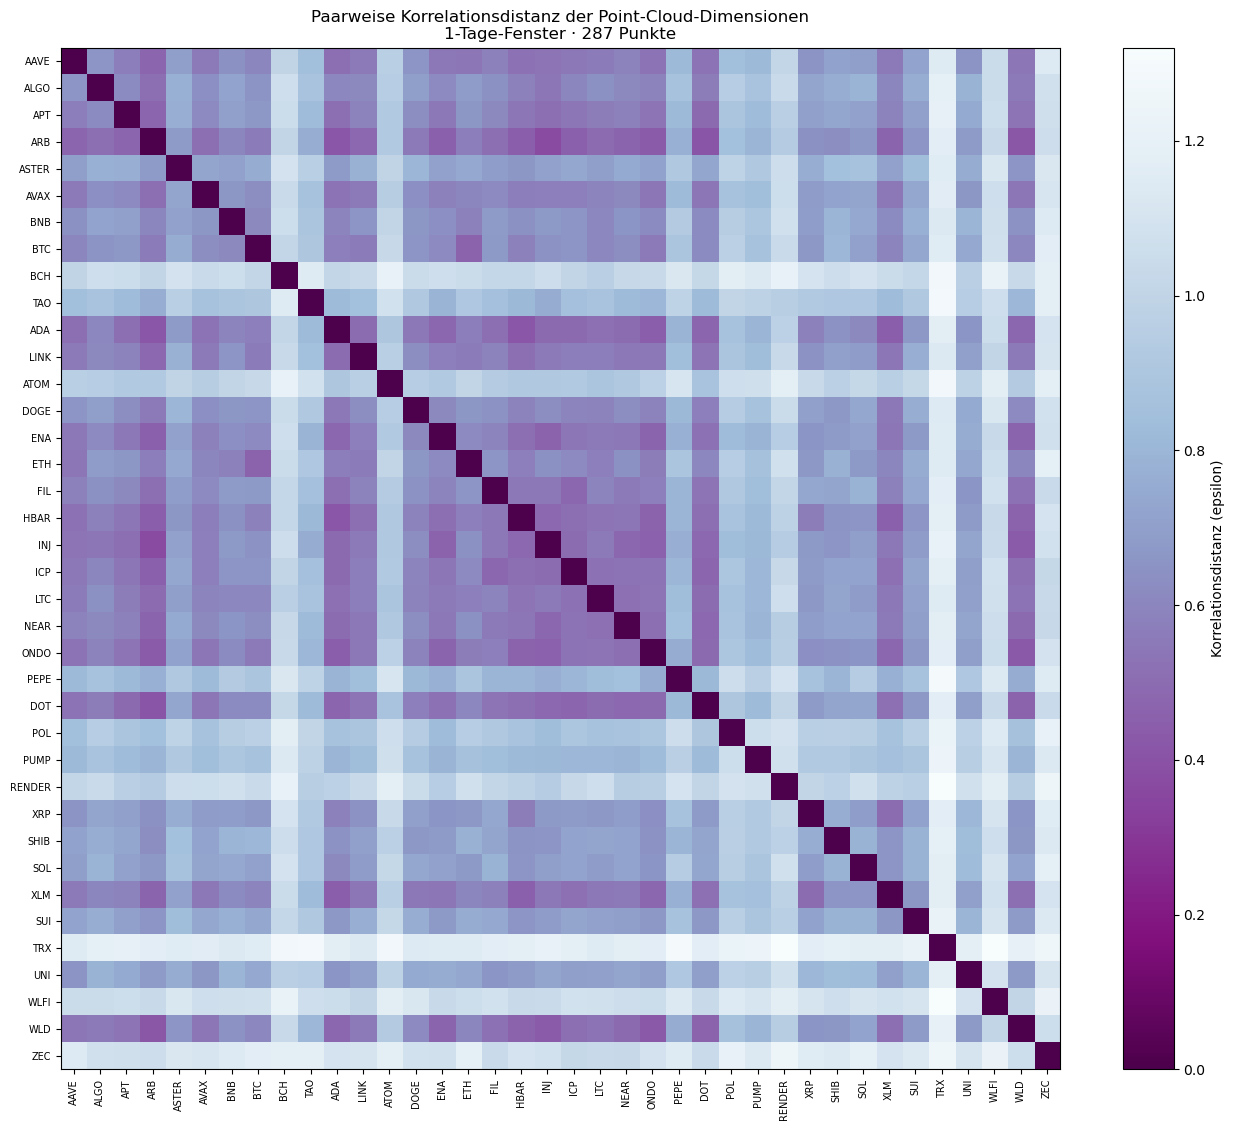

Top-10 Paare mit kleinster Distanz (staerkste Ko-Bewegung):
ARB   INJ     0.376018
      DOT     0.408154
ADA   HBAR    0.415082
ARB   ADA     0.417480
      WLD     0.421200
ONDO  WLD     0.425697
ARB   ONDO    0.433622
INJ   WLD     0.436731
ARB   HBAR    0.444665
ADA   XLM     0.447362
dtype: float64

Top-5 Paare mit groesster Distanz (am wenigsten verwandt):
ATOM    TRX     1.276160
TAO     TRX     1.286017
PEPE    TRX     1.299523
RENDER  TRX     1.316066
TRX     WLFI    1.320560


In [ ]:
# --- Visualisierung 4: Distanz-Heatmap aller Assets ---
dist_df = pd.DataFrame(dist_matrix, columns=syms, index=syms)

fig, ax = plt.subplots(figsize=(max(8, len(syms) * 0.35), max(6, len(syms) * 0.3)))
colormax=dist_df.values.max()
im = ax.imshow(dist_df.values, vmin=0, vmax=colormax, cmap="BuPu_r", aspect="auto")
plt.colorbar(im, ax=ax, label="Korrelationsdistanz (epsilon)")
ax.set_xticks(range(len(syms))); ax.set_xticklabels(syms, rotation=90, fontsize=7)
ax.set_yticks(range(len(syms))); ax.set_yticklabels(syms, fontsize=7)
ax.set_title(f"Paarweise Korrelationsdistanz der Point-Cloud-Dimensionen\n{WINDOW_DAYS}-Tage-Fenster · {result['n_points']} Punkte")
plt.tight_layout()
plt.savefig("viz4_heatmap.png", dpi=120)
plt.show()
plt.close("all")

# Kleine Distanz = aehnliches Verhalten -> aufsteigend sortieren fuer die "engsten" Paare.
pairs = (dist_df.where(np.triu(np.ones(dist_df.shape), k=1).astype(bool)).stack().sort_values(ascending=True))
print("Top-10 Paare mit kleinster Distanz (staerkste Ko-Bewegung):")
print(pairs.head(10))
print("\nTop-5 Paare mit groesster Distanz (am wenigsten verwandt):")
print(pairs.tail(5).to_string())

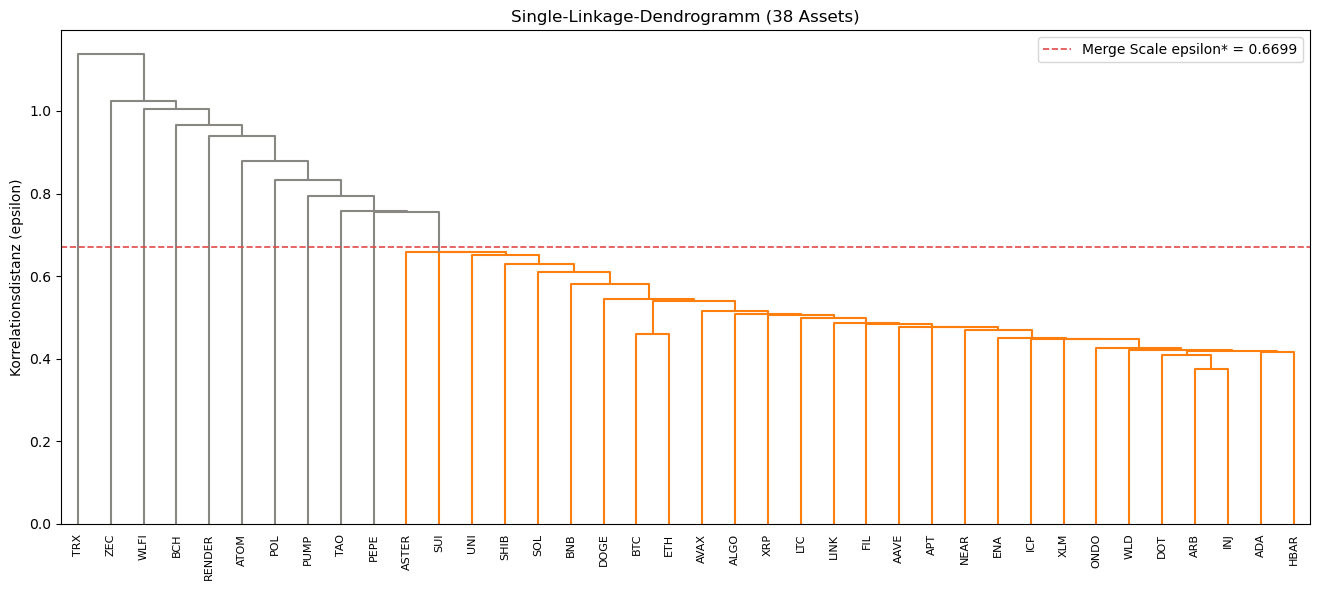

In [ ]:
# --- Visualisierung 5: Dendrogramm der Assets ---
# Zeigt den Cluster-Baum: Assets, die frueh (niedrige Distanz) zusammengefuehrt
# werden, haben ein sehr aehnliches Return-Verhalten. Je hoeher der Merge-Punkt
# auf der y-Achse, desto schwaecher die Verbindung.
from cloudvisualisation import plot_dendrogram

merge_scale = 0.6699  # Beispiel-Schwelle fuer die Cluster-Einfaerbung
z_dendro = plot_dendrogram(dist_matrix, syms, color_threshold=merge_scale)

In [ ]:
# --- Visualisierung 7: Epsilon-Slider (Vietoris-Rips 1-Skelett) ---
# Assets als Knoten (MDS-Layout aus der Distanzmatrix). Kanten erscheinen, sobald
# die paarweise Korrelationsdistanz <= epsilon ist. Beim Hochziehen des Sliders sieht
# man live, wie isolierte Assets (epsilon=0) zu Cliquen verschmelzen.
from cloudvisualisation import plot_vietoris_rips_epsilon_slider

plot_vietoris_rips_epsilon_slider(dist_matrix, syms)

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='epsilon:', layout=Layout(wi…

In [ ]:
# --- Visualisierung 8: H0-Persistenz-Barcode ---
# Ein Balken pro Merge-Event (birth=0 -> death=epsilon). Lange Balken mit vielen
# beteiligten Assets = strukturell stabile Cliquen (hohe Persistenz = robust gegen
# Marktvolatilitaet, siehe PDF "Another important point").
from cloudvisualisation import plot_h0_persistence_barcode

z_linkage = plot_h0_persistence_barcode(dist_matrix, syms)

print(f"\nGroesste Merge-Events")
merge_df = pd.DataFrame(z_linkage, columns=["cluster_1", "cluster_2", "death", "size"])
print(merge_df.sort_values("death", ascending=False).head(5).to_string(index=False))

Anzahl Cluster-Intervalle: 74

Groesste Merge-Events
 cluster_1  cluster_2    death  size
      33.0       73.0 1.138229  38.0
      37.0       72.0 1.024950  37.0
      35.0       71.0 1.004431  36.0
       8.0       70.0 0.965029  35.0
      27.0       69.0 0.938633  34.0


In [ ]:
# --- Visualisierung 6: Interaktive 3D Point Cloud (frei wählbare Achsen) ---
# X/Y/Z-Achse per Dropdown beliebig auf ein Asset legen -> "durch" die
# n-dimensionale Wolke wandern. Farbe = Return auf der X-Achse (diverging).
from cloudvisualisation import plot_point_cloud_3d_interactive

plot_point_cloud_3d_interactive(pc, syms, timestamps=result["timestamps"])


interactive(children=(Dropdown(description='X-Achse:', options=('AAVE', 'ALGO', 'APT', 'ARB', 'ASTER', 'AVAX',…